# ¿Quién gana? Antes y durante una partida de League of Legends

Partidas clasificatorias de Diamante para arriba en el servidor de Latinoamérica Sur. Se predice la probabilidad de
que gane el **lado azul** con dos modelos: uno **antes de la partida** (campeones elegidos e historial de los diez
jugadores) y otro **en vivo**, a los minutos 10, 15 y 20.

Todas las métricas se muestran con su intervalo de confianza del 95 % (IC), por bootstrap de partidas salvo que se
indique otra cosa.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))
from src.informe import figuras as F

## 1. La pregunta y los datos

Cada modelo se ajusta con partidas anteriores a las que predice: el tiempo es la única partición. Las variantes se
eligen con bloques que avanzan hacia adelante y con la ventana de validación **V**; el **test** queda cerrado hasta
la evaluación final.

In [2]:
F.tabla_datos()

Tramo,Fechas,Partidas,Para qué
Ajuste,nov. 2024 → 15/09,118.064,Master+ anteriores a V; con ellas se estiman los pesos
Bloques hacia adelante,07/09 → 15/09,4.749 / 4.607 / 4.504,cada bloque se predice con lo anterior: elige variantes sin mirar V
Validación (V),16/09 → 26/09,16.428,lobbies Master+; se mira una vez por variante
Diamante de la ventana de V,16/09 → 26/09,10.506,control: nunca se usó para decidir
Test,desde el 27/09,38.013,"94,5 % Master; se evalúa una sola vez"


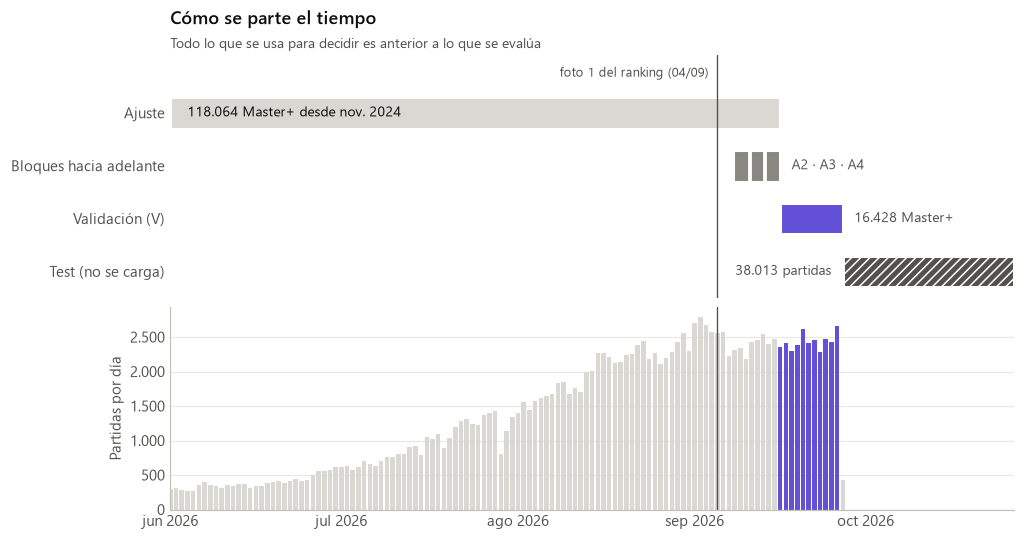

In [3]:
F.fig_linea_tiempo()

## 2. Antes de la partida

Una regresión logística sobre **diferencias entre equipos**: cada variable entra como azul − rojo.

$$\operatorname{logit} P(\text{gana azul}) = \beta_0 + \sum_k \beta_k \left(x_k^{\text{azul}} - x_k^{\text{rojo}}\right)$$

**Por qué así.** Si se intercambian los lados, todas las diferencias cambian de signo y la predicción pasa a
$\sigma(\beta_0 - \sum_k \beta_k \Delta x_k)$: sin $\beta_0$ el modelo sería exactamente antisimétrico,
$P(a, b) = 1 - P(b, a)$. Toda la ventaja del lado rojo queda en un solo número, $\beta_0$, en lugar de contaminar los
coeficientes de las variables. La penalización L2 mantiene estables las ~1.500 columnas (los campeones por línea son
la mayoría).

In [4]:
F.respuesta_previo()

**Respuesta.** En V Master+, entre una partida que ganó el azul y otra que ganó el rojo, el modelo le da más chances al azul en la primera el 67,3 % de las veces (AUC 0,6727 [0,6644; 0,6807]), y acierta el ganador en el 62,4 % [61,7; 63,2], contra 52,2 % de apostar siempre al rojo.

In [5]:
F.tabla_previo()

V Master+ (16.428 partidas),Valor [IC 95 %]
AUC,"0,6727 [0,6644; 0,6807]"
Acierto,"62,4 % [61,7; 63,2]"
Acierto de «siempre rojo»,"52,2 % [51,4; 52,9]"
Log loss,"0,6451 [0,6404; 0,6501]"
"Error de calibración (ECE, 10 deciles)","0,0109"


**Qué aporta cada grupo.** El salto más grande lo da conocer al jugador *con ese campeón y en esa línea*; el resto
suma de a milésimas, y cada paso se aceptó solo si mejoraba en V y en los bloques hacia adelante. Las dos últimas
filas no agregan información: corrigen datos que en el ajuste sabían algo del futuro, y por eso restan.

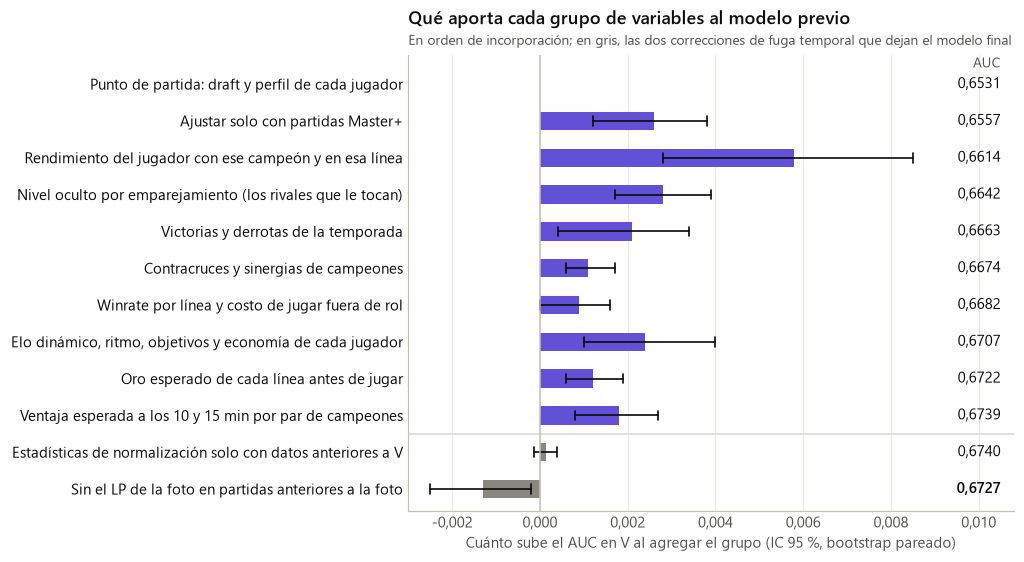

In [6]:
F.fig_aportes_previo()

**Qué tan confiable es cada probabilidad.** El AUC es la probabilidad de que el modelo ordene bien un par al azar,
$\text{AUC} = P(\hat p_i > \hat p_j \mid i \text{ ganó el azul},\ j \text{ ganó el rojo})$. Las predicciones están
calibradas (cuando dice 70 %, el azul gana cerca del 70 %), y en las partidas donde está más seguro acierta mucho más
que el promedio.

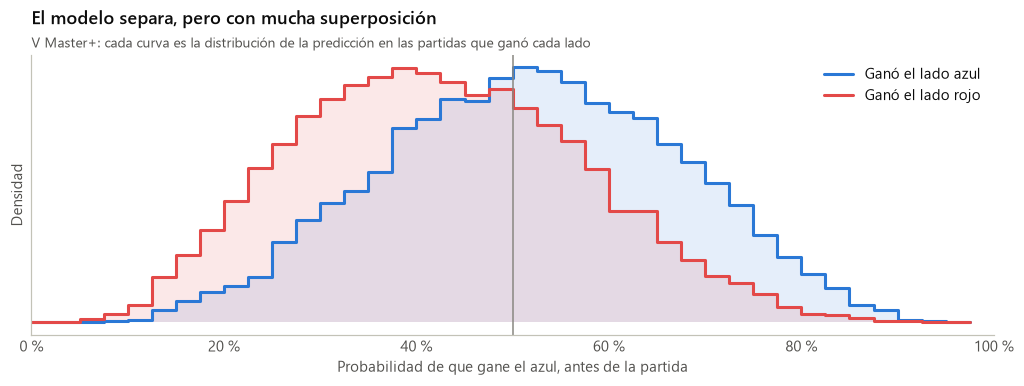

In [7]:
F.fig_separacion_previo()

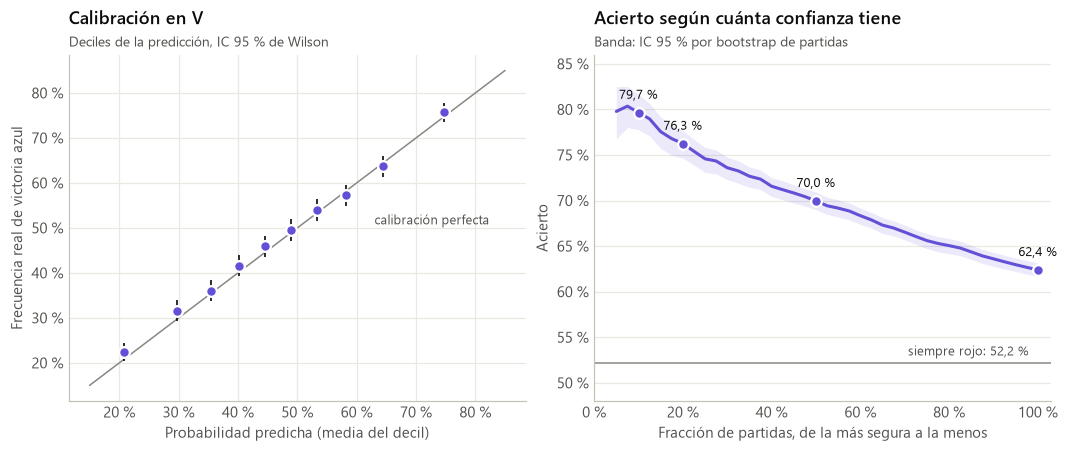

In [8]:
F.fig_calibracion_cobertura()

## 3. Durante la partida

Al minuto $m$ se suma el estado de la partida, $\mathbf x_m$ (oro, experiencia, nivel, súbditos, daño, asesinatos,
muertes y asistencias por línea, azul − rojo, y la *sorpresa* de cada línea: lo que lleva menos lo que se esperaba
antes de jugar), al logit del modelo previo, $L$:

$$\hat P_m = \sigma\!\left(\beta_0 + \beta_L\, L + \boldsymbol\beta^\top \mathbf x_m\right)$$

Se ajusta solo con partidas Master+ anteriores a V, una regresión por minuto, con las partidas que siguen vivas en
ese minuto.

In [9]:
F.respuesta_en_vivo()

**Respuesta.** Sobre las mismas 14.971 partidas de V, el AUC pasa de 0,6610 antes de jugar a 0,7619 / 0,8168 / 0,8726 a los 10 / 15 / 20 minutos, y el acierto de 61,6 % a 69,3 % / 74,1 % / 78,7 % (IC en la tabla). Antes de jugar estas partidas son más difíciles que el promedio de V: las que terminan antes del minuto 20 suelen ser las más desparejas.

In [10]:
F.tabla_en_vivo()

Momento,"AUC, misma cohorte (14.971)","Acierto, misma cohorte",AUC · acierto con todas las vivas (n)
Antes (solo el previo),"0,6610 [0,6522; 0,6695]","61,6 % [60,8; 62,4]",—
Minuto 10,"0,7619 [0,7546; 0,7696]","69,3 % [68,6; 70,1]","0,7883 · 71,4 % (16.331)"
Minuto 15,"0,8168 [0,8099; 0,8233]","74,1 % [73,4; 74,8]","0,8411 · 76,1 % (16.238)"
Minuto 20,"0,8726 [0,8666; 0,8782]","78,7 % [78,1; 79,4]","0,8726 · 78,7 % (14.971)"


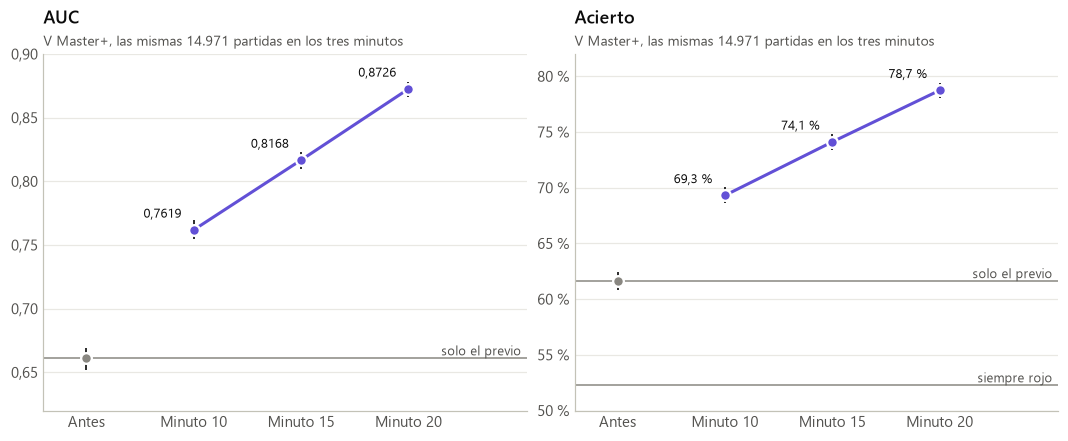

In [11]:
F.fig_en_vivo_minutos()

**Cuánto suma lo previo.** Aun viendo el oro y las bajas, saber quiénes juegan y qué eligieron sigue sumando, cada
vez menos a medida que la partida avanza. Los dos primeros puntos de cada minuto vienen de una medición anterior que
no guardó las predicciones, por eso no tienen IC.

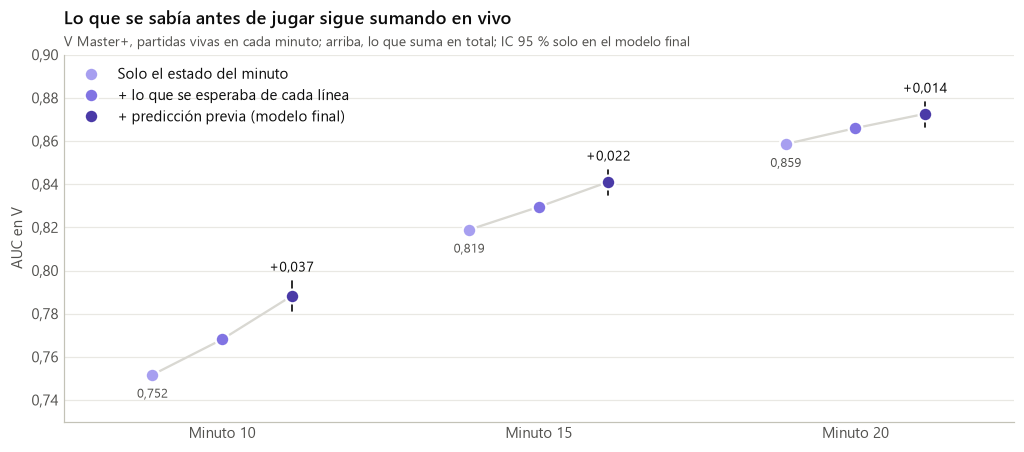

In [12]:
F.fig_suma_previo()

## 4. Resultado en el test

Los dos modelos, congelados, se evalúan **una sola vez** en el test (desde el 27/09): AUC, acierto contra «siempre
rojo», log loss y error de calibración, con IC por bootstrap por bloques de días.

In [13]:
F.seccion_test()

modelo,minuto,conjunto,n,auc,auc_lo,auc_hi,acierto,acierto_lo,acierto_hi,log_loss,log_loss_lo,log_loss_hi,ece,ece_lo,ece_hi,siempre_rojo,siempre_rojo_lo,siempre_rojo_hi
previo,nan,evaluacion,37196,0.676500,0.672100,0.681100,0.629900,0.626000,0.633700,0.641900,0.639500,0.644200,0.006000,0.005300,0.012700,0.525100,0.519900,0.529700
previo,nan,evaluacion,37196,0.676500,0.671000,0.681900,0.629900,0.625100,0.634900,0.641900,0.638800,0.645100,0.006000,0.005600,0.012900,0.525100,0.519800,0.529800
previo,nan,evaluacion MASTER,35133,0.677800,0.673500,0.682400,0.630400,0.626500,0.634200,0.641000,0.638400,0.643500,0.006200,0.005500,0.012600,0.525900,0.520400,0.530700
previo,nan,evaluacion GRANDMASTER,1724,0.644600,0.618200,0.666600,0.612500,0.593400,0.632600,0.661400,0.647700,0.677000,0.033500,0.028000,0.060000,0.512800,0.486000,0.537700
previo,nan,evaluacion CHALLENGER,339,0.695500,0.636800,0.749900,0.657800,0.597600,0.714800,0.635000,0.605600,0.668400,0.091400,0.071800,0.159800,0.498500,0.449700,0.552900
previo,nan,diamante (chequeo),33998,0.647300,0.641400,0.653400,0.604700,0.599400,0.610000,0.660200,0.656700,0.663700,0.024300,0.020000,0.030300,0.501400,0.496100,0.506900
en_vivo,10.000000,evaluacion,36983,0.791600,0.788000,0.795300,0.716000,0.712300,0.719800,0.548600,0.544600,0.552300,0.004100,0.004300,0.010600,0.525300,0.520200,0.529800
en_vivo,10.000000,evaluacion,36983,0.791600,0.787100,0.796000,0.716000,0.711300,0.720300,0.548600,0.544200,0.553000,0.004100,0.004400,0.010400,0.525300,0.520100,0.530500
en_vivo,10.000000,cohorte 20,33821,0.765900,0.761500,0.770600,0.696100,0.691600,0.701000,0.575200,0.570600,0.579600,0.010600,0.007900,0.015500,0.526400,0.521700,0.530900
previo_hacia_adelante,10.000000,cohorte 20,33821,0.668100,0.663700,0.672600,0.624500,0.620500,0.628500,0.646700,0.644300,0.649200,0.008200,0.007100,0.014700,0.526400,0.521700,0.530900


**¿Se sostiene lo que se midió en V?** Con la misma definición en los dos conjuntos (las partidas que siguen vivas al
minuto 20), el test da lo mismo que V o apenas más, en los cuatro momentos: no hubo sobreajuste a V por haber elegido
el modelo mirándola. En esta cohorte el previo da 0,668; sobre todas las partidas del test, 0,6765 (la tabla de arriba).

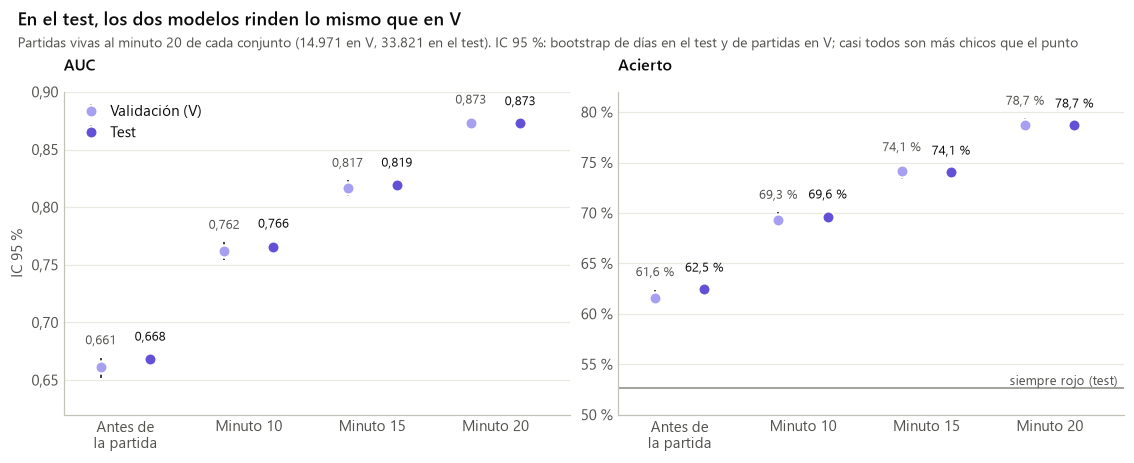

In [14]:
F.fig_test_vs_v()

**El recorrido.** Cada barra es un hito del modelo previo, medido en la misma V Master+; la última, el modelo final
en el test. El salto grande es pasar de saber qué campeones se eligieron a saber quién juega (+5,8 puntos con el
stacking); de ahí en adelante cada paso suma décimas. Las dos correcciones de fuga cuestan 0,2 puntos.

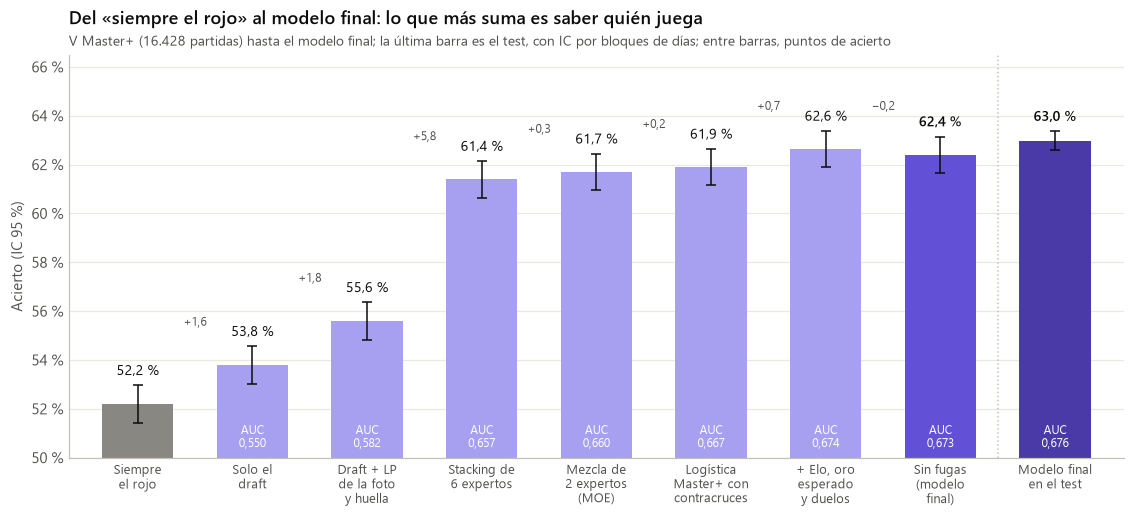

In [15]:
F.fig_recorrido_previo()

**Contra un trabajo publicado.** DraftRec (Lee et al., WWW 2022) predice el ganador en Master+ y Diamante con
el draft y el historial de cada jugador. Corrimos nuestro modelo previo (con todo lo que su dataset
permite reconstruir: variables por línea, rating causal, contracruces y sinergias) sobre su misma partición, y en
las mismas 28.690 partidas de su test acierta 3,9 puntos más. Su dataset no tiene LP, fechas, rango ni W/L de la
temporada, así que esa comparación deja afuera parte de lo que usa nuestro modelo en nuestros datos.

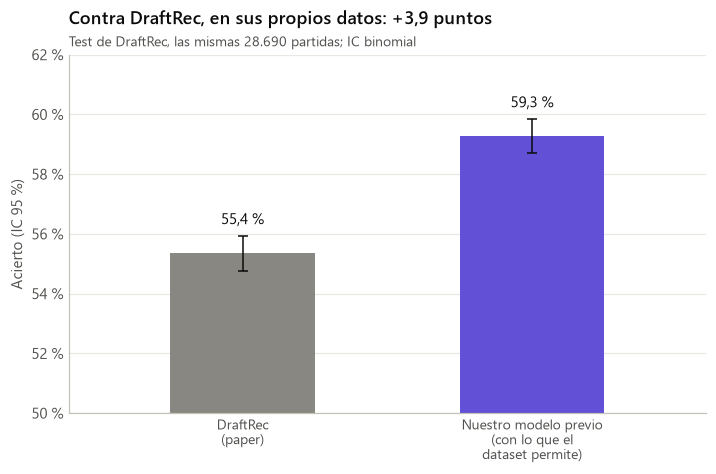

In [16]:
F.fig_draftrec()

## 5. Robustez

**¿Se degrada con el tiempo?** Dentro de V, partida en cuatro ventanas cronológicas del mismo tamaño, el AUC no
muestra una tendencia distinguible de cero en ninguno de los dos modelos (la pendiente lleva su IC).

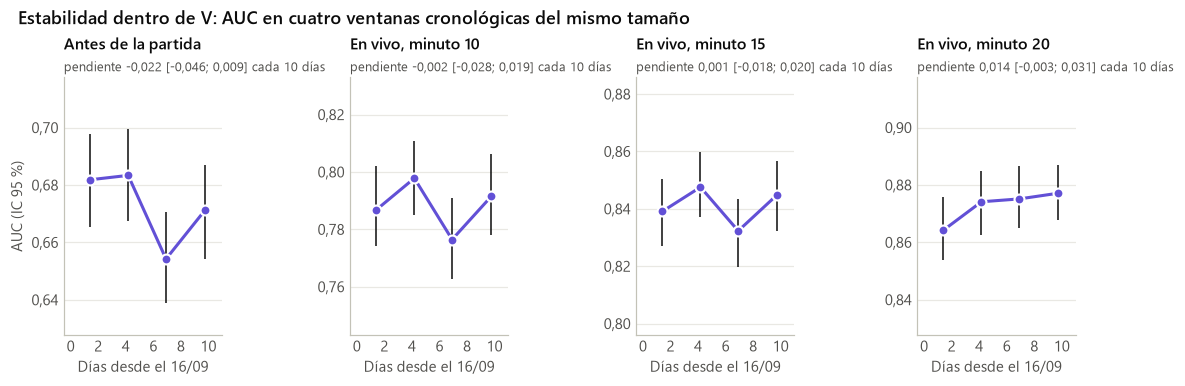

In [17]:
F.fig_degradacion_v()

En el test se repite la misma medición por ventanas y, además, la variación entre 5 semillas fijadas de antemano.

In [18]:
F.seccion_robustez_test()

modelo,minuto,semilla,auc,acierto,log_loss,ece,siempre_rojo,ventaja_rojo
previo,nan,42,0.676500,0.629900,0.641900,0.006000,0.525100,0.104800
previo,nan,0,0.676600,0.630100,0.641800,0.006300,0.525100,0.105000
previo,nan,1,0.676300,0.629700,0.642000,0.006400,0.525100,0.104600
previo,nan,2,0.676300,0.629600,0.642000,0.005700,0.525100,0.104500
previo,nan,3,0.676400,0.629900,0.641900,0.006500,0.525100,0.104800
en_vivo,10.000000,42,0.791600,0.716000,0.548600,0.004100,0.525300,0.190700
en_vivo,10.000000,0,0.791600,0.715500,0.548600,0.004800,0.525300,0.190200
en_vivo,10.000000,1,0.791600,0.715500,0.548700,0.004500,0.525300,0.190200
en_vivo,10.000000,2,0.791500,0.715700,0.548700,0.004400,0.525300,0.190400
en_vivo,10.000000,3,0.791600,0.716000,0.548700,0.004100,0.525300,0.190700


## 6. Dos preguntas laterales

**Huella de estilo.** ¿Se puede reconocer a una persona por cómo juega, aunque cambie de campeón? Con jugadores que
el modelo nunca vio y campeones distintos de cada lado, una red contrastiva lo logra con AUC cercano a 0,9 a partir
de 10 partidas, y sube con más partidas.

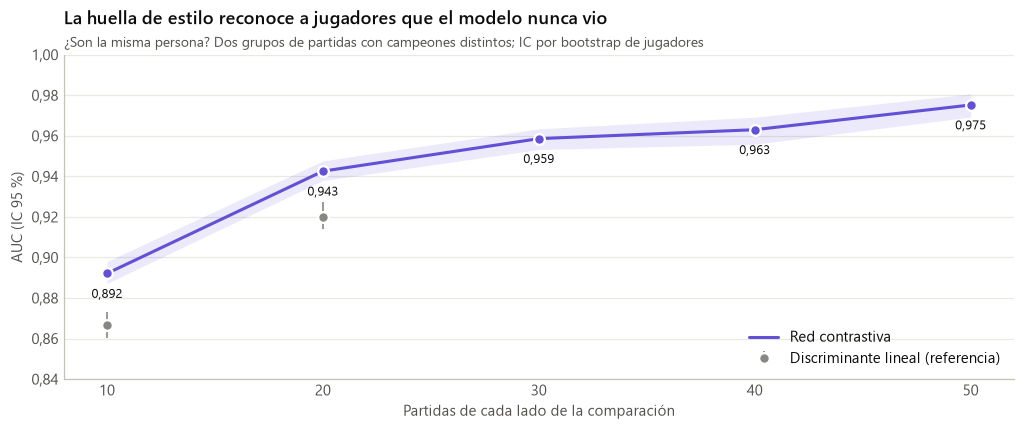

In [19]:
F.fig_huella()

**Matchmaking.** Si se reacomodan los mismos diez jugadores entre equipos y líneas, sin que nadie pase a un rol que
juega menos, el desbalance que estima el modelo se reduce a la mitad. Es una **simulación bajo el modelo**: esas
partidas no se jugaron, y no se pueden respetar dúos ni grupos porque los datos no los registran.

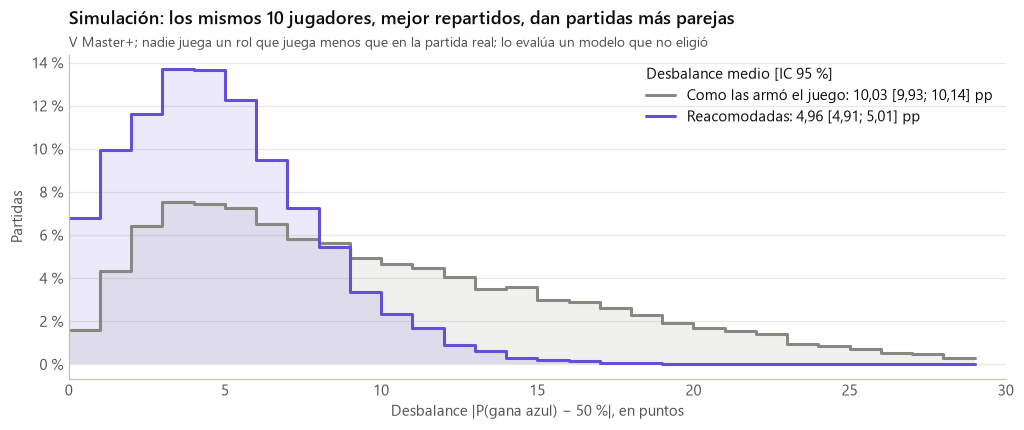

In [20]:
F.fig_matchmaking()

## 7. Limitaciones

- **Elegido mirando V.** Unas 40 variantes del modelo previo se compararon en V; los bloques hacia adelante y las
  partidas de Diamante de la misma ventana sirven de control, pero el número que vale es el del test.
- **El test se mira una sola vez**, con el protocolo fijado antes de cargarlo.
- **Eventos del timeline** (dragones, primera sangre, oro sin gastar) suman en vivo en V y en los bloques, pero no se
  presentan: no hay timelines de las partidas de Diamante de la ventana para replicarlo.
- **Las partidas largas son casi impredecibles antes de jugar**: lo previo sirve sobre todo cuando la partida se
  define temprano.
- **Datos que no están**: bans, rol pedido y autofill exacto; el rol es el jugado.
- **Un servidor y una temporada**: Master+ de Latinoamérica Sur, con casi todas las partidas entre junio y
  septiembre de 2026.